In [1]:
# Humedad relativa del aire - Barranquilla
# datos sacados de datos.gov.co (IDEAM)
# https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Humedad-del-Aire/uext-mhny/data_preview

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

In [2]:
archivo = "Humedad_del_Aire_20261028.csv"
df = pd.read_csv("/content/Humedad_del_Aire_20261028.csv")
print(df.shape)
print(df.head(15))

(119575, 12)
    CodigoEstacion  CodigoSensor         FechaObservacion  ValorObservado  \
0         29004520            27  2007 Jul 28 03:00:00 PM              76   
1         29004520            27  2013 Jan 24 08:00:00 AM               0   
2         29004520            27  2009 Aug 25 10:00:00 PM               0   
3         29004520            27  2008 Jun 26 06:00:00 AM              88   
4         29004520            27  2011 Oct 07 02:00:00 PM               0   
5         29004520            27  2010 Nov 16 11:00:00 AM               0   
6         29004520            27  2018 Feb 21 07:00:00 PM              78   
7         29004520            27  2016 Dec 28 08:00:00 AM              84   
8         29004520            27  2018 Feb 13 11:00:00 PM              81   
9         29004520            27  2018 Nov 23 09:00:00 PM              87   
10        29004520            27  2013 Jul 17 11:00:00 PM              88   
11        29004520            27  2006 Nov 02 05:00:00 PM      

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119575 entries, 0 to 119574
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   CodigoEstacion     119575 non-null  int64
 1   CodigoSensor       119575 non-null  int64
 2   FechaObservacion   119575 non-null  str  
 3   ValorObservado     119575 non-null  int64
 4   NombreEstacion     119575 non-null  str  
 5   Departamento       119575 non-null  str  
 6   Municipio          119575 non-null  str  
 7   ZonaHidrografica   119575 non-null  str  
 8   Latitud            119575 non-null  str  
 9   Longitud           119575 non-null  str  
 10  DescripcionSensor  119575 non-null  str  
 11  UnidadMedida       119575 non-null  str  
dtypes: int64(3), str(9)
memory usage: 10.9 MB


In [4]:
print(df["DescripcionSensor"].value_counts())
print(df["Municipio"].value_counts())

print("vacíos:", df["ValorObservado"].isnull().sum())
print("ceros:", (df["ValorObservado"] == 0).sum())
print("duplicados:", df.duplicated().sum())
print(df["ValorObservado"].describe())

DescripcionSensor
Humedad del aire 2 mt            103088
HUMEDAD DEL SUELO A 1 m Ó MAS     16487
Name: count, dtype: int64
Municipio
BARRANQUILLA    119118
Barranquilla       457
Name: count, dtype: int64
vacíos: 0
ceros: 25394
duplicados: 3519
count    119575.00000
mean         67.29987
std          36.22527
min           0.00000
25%          69.00000
50%          83.00000
75%          91.00000
max         100.00000
Name: ValorObservado, dtype: float64


In [5]:
# Limpieza
# el archivo trae humedad del suelo tambien, solo dejo la del aire
df = df[df["DescripcionSensor"] == "Humedad del aire 2 mt"].reset_index(drop=True)
print(df.shape)

# barranquilla viene escrito de 2 formas
df["Municipio"] = df["Municipio"].str.upper()
print(df["Municipio"].value_counts())

df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(103088, 12)
Municipio
BARRANQUILLA    103088
Name: count, dtype: int64


(102224, 12)


In [6]:
# humedad en 0 no tiene sentido, es error del sensor
df = df[df["ValorObservado"] > 0].reset_index(drop=True)

df["FechaObservacion"] = pd.to_datetime(df["FechaObservacion"], format="%Y %b %d %I:%M:%S %p", errors="coerce")
df["ANIO"] = df["FechaObservacion"].dt.year
df["NUM_MES"] = df["FechaObservacion"].dt.month
df = df.dropna(subset=["FechaObservacion"]).reset_index(drop=True)

# solo me quedo con lo que voy a usar
df = df[["FechaObservacion", "ANIO", "NUM_MES", "NombreEstacion", "Municipio", "ValorObservado"]]
df = df.rename(columns={"ValorObservado": "HUMEDAD"})
print("vacíos:", df["HUMEDAD"].isnull().sum())
print(df.shape)
print(df["HUMEDAD"].describe())

vacíos: 0
(82594, 6)
count    82594.000000
mean        84.711492
std          9.653961
min          2.000000
25%         78.000000
50%         85.000000
75%         91.000000
max        100.000000
Name: HUMEDAD, dtype: float64


In [7]:
# saco 10000 datos
df = df.sample(n=10000, random_state=42).sort_values("FechaObservacion").reset_index(drop=True)
print(df.shape)
print(df.head(15))

(10000, 6)
      FechaObservacion  ANIO  NUM_MES                     NombreEstacion  \
0  2006-10-10 15:00:00  2006       10  ESCUELA NAVAL BARRANQUILLA  - AUT   
1  2006-10-11 01:00:00  2006       10  ESCUELA NAVAL BARRANQUILLA  - AUT   
2  2006-10-11 06:00:00  2006       10  ESCUELA NAVAL BARRANQUILLA  - AUT   
3  2006-10-18 22:00:00  2006       10  ESCUELA NAVAL BARRANQUILLA  - AUT   
4  2006-10-19 07:00:00  2006       10  ESCUELA NAVAL BARRANQUILLA  - AUT   
5  2006-10-19 18:00:00  2006       10  ESCUELA NAVAL BARRANQUILLA  - AUT   
6  2006-10-20 02:00:00  2006       10  ESCUELA NAVAL BARRANQUILLA  - AUT   
7  2006-10-20 06:00:00  2006       10  ESCUELA NAVAL BARRANQUILLA  - AUT   
8  2006-10-20 10:00:00  2006       10  ESCUELA NAVAL BARRANQUILLA  - AUT   
9  2006-10-20 11:00:00  2006       10  ESCUELA NAVAL BARRANQUILLA  - AUT   
10 2006-10-20 13:00:00  2006       10  ESCUELA NAVAL BARRANQUILLA  - AUT   
11 2006-10-20 19:00:00  2006       10  ESCUELA NAVAL BARRANQUILLA  - AUT   
1

In [8]:
# menos de 75 baja, de 75 a 88 media, mas de 88 alta
clase = []
for h in df["HUMEDAD"]:
    if h < 75:
        clase.append("Baja")
    elif h < 88:
        clase.append("Media")
    else:
        clase.append("Alta")

df["CLASE"] = clase
print(df["CLASE"].value_counts())

CLASE
Media    4654
Alta     3836
Baja     1510
Name: count, dtype: int64


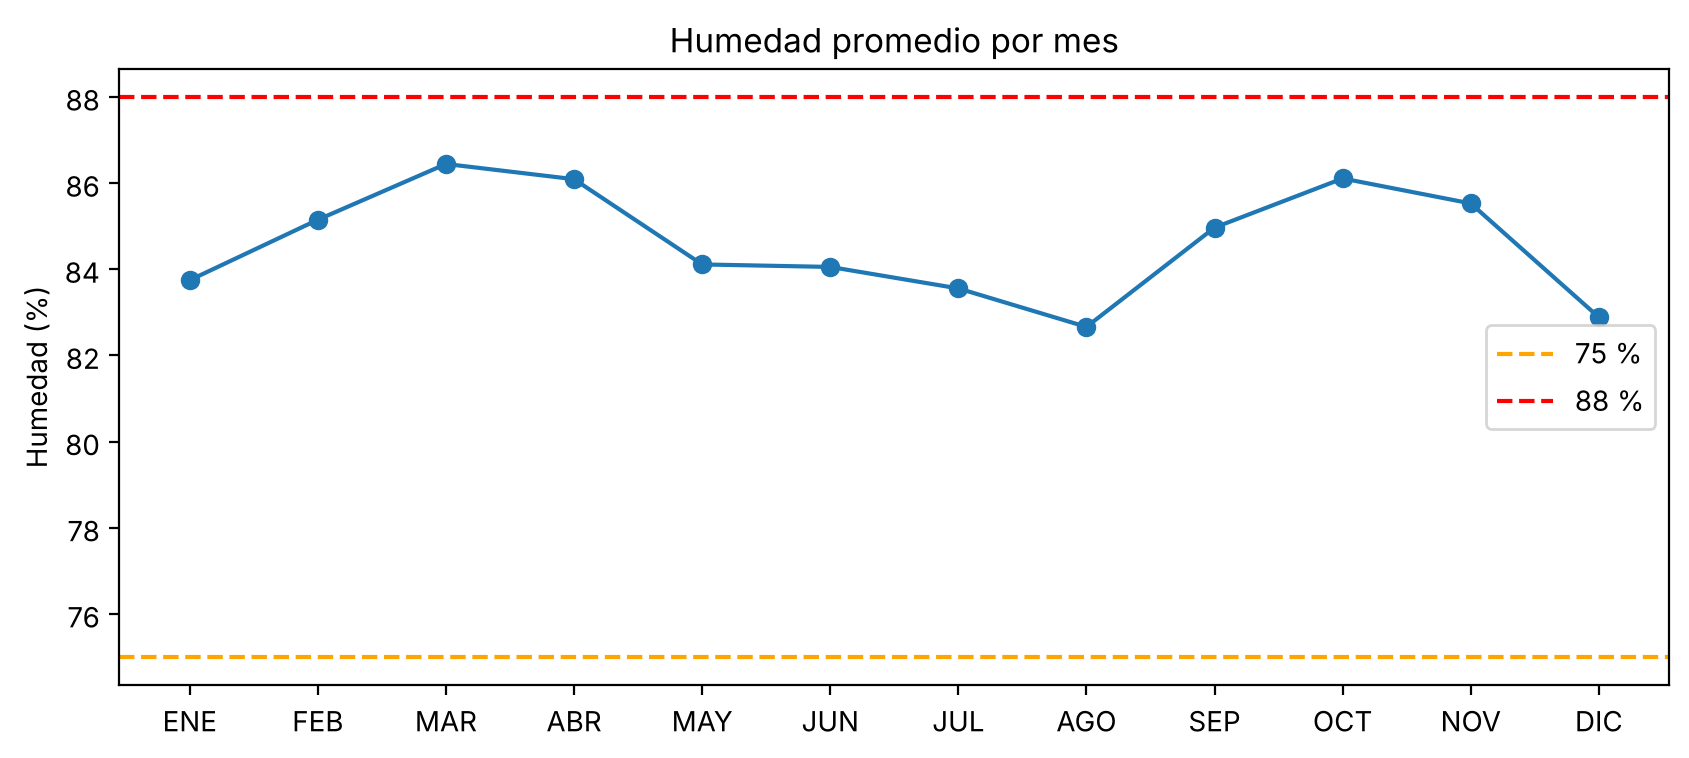

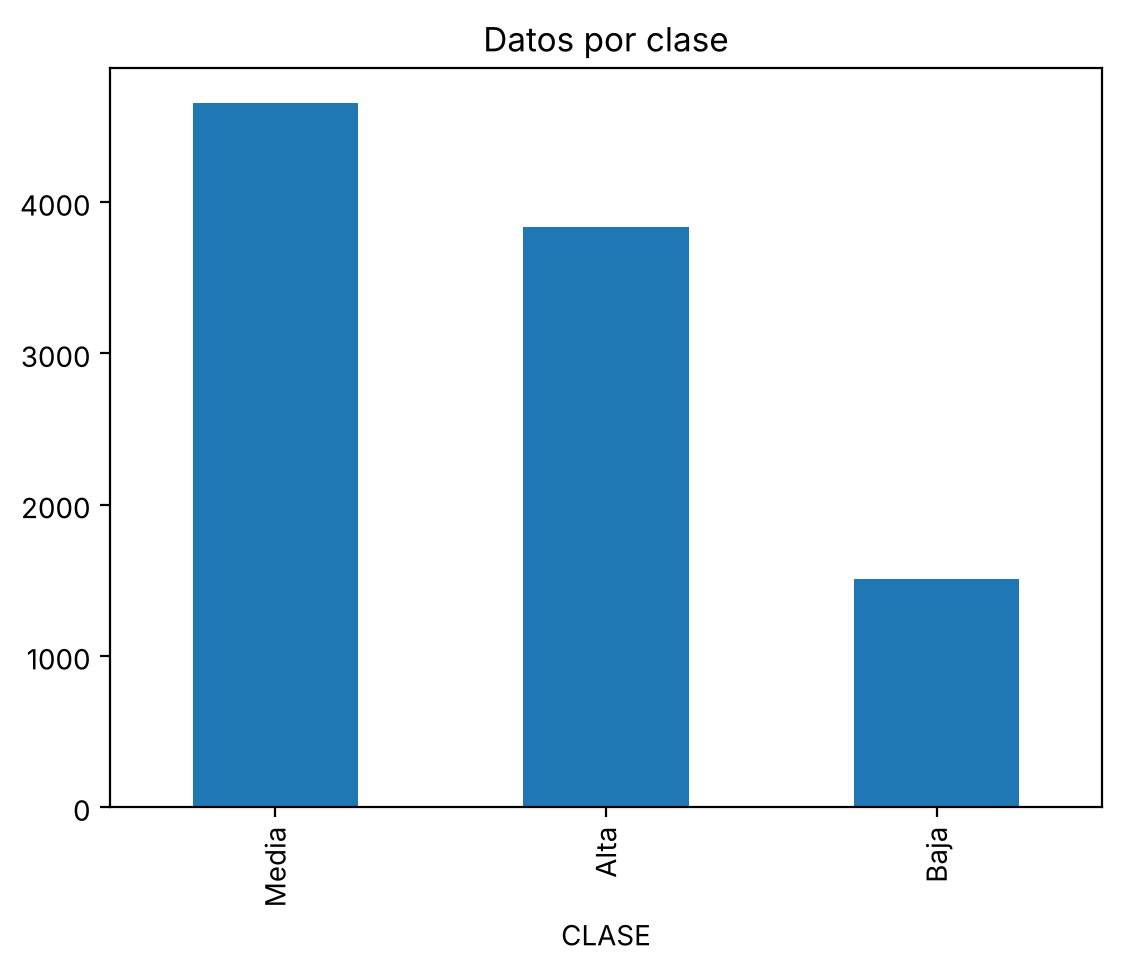

In [9]:
meses = ["ENERO","FEBRERO","MARZO","ABRIL","MAYO","JUNIO","JULIO","AGOSTO",
         "SEPTIEMBRE","OCTUBRE","NOVIEMBRE","DICIEMBRE"]
promedio = df.groupby("NUM_MES")["HUMEDAD"].mean()

plt.figure(figsize=(10,4))
plt.plot(promedio.index, promedio.values, marker="o")
plt.axhline(75, color="orange", linestyle="--", label="75 %")
plt.axhline(88, color="red", linestyle="--", label="88 %")
plt.xticks(range(1,13), [m[:3] for m in meses])
plt.ylabel("Humedad (%)")
plt.title("Humedad promedio por mes")
plt.legend()
plt.show()

df["CLASE"].value_counts().plot(kind="bar")
plt.title("Datos por clase")
plt.show()

Precisión: 1.0
[[ 959    0    0]
 [   0  378    0]
 [   0    0 1163]]


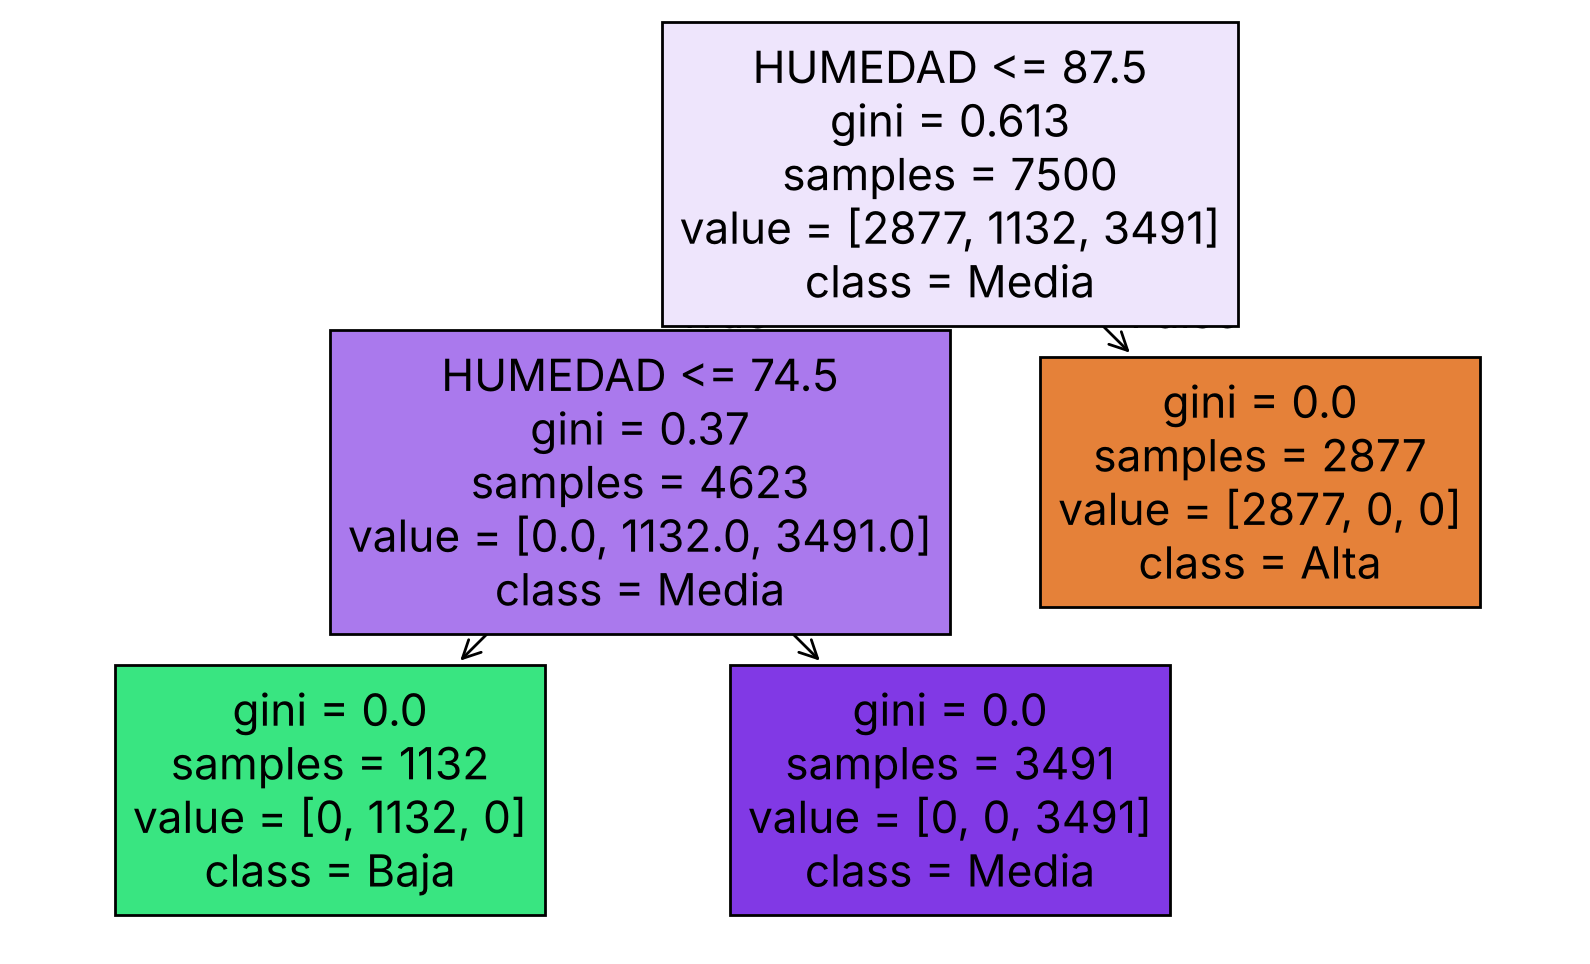

In [10]:
# Arbol de decisión
X = df[["HUMEDAD"]]
y = df["CLASE"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(X_train, y_train)

y_pred = arbol.predict(X_test)
print("Precisión:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

plt.figure(figsize=(10,6))
plot_tree(arbol, feature_names=["HUMEDAD"], class_names=arbol.classes_, filled=True)
plt.show()

In [11]:
# Predicción
h = 65
print(h, "% ->", arbol.predict(pd.DataFrame({"HUMEDAD": [h]}))[0])
h = 80
print(h, "% ->", arbol.predict(pd.DataFrame({"HUMEDAD": [h]}))[0])
h = 92
print(h, "% ->", arbol.predict(pd.DataFrame({"HUMEDAD": [h]}))[0])

65 % -> Baja
80 % -> Media
92 % -> Alta
